In [1]:
# Cell 1: Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Load Tanishq's preprocessed dataset
df = pd.read_csv('processed_insurance.csv')

# Split data using Tanishq's split column
train_df = df[df['split'] == 'train'].drop(columns=['split'])
test_df = df[df['split'] == 'test'].drop(columns=['split'])

# Separate features (X) and target (y)
X_train = train_df.drop(columns=['charges'])
y_train = train_df['charges']

X_test = test_df.drop(columns=['charges'])
y_test = test_df['charges']

print("Data loaded successfully!")
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Data loaded successfully!
Training samples: 1070, Testing samples: 268


In [2]:
# Cell 2: Baseline Model (BMI Only)
X_train_bmi = X_train[['bmi']]
X_test_bmi = X_test[['bmi']]

baseline_model = LinearRegression()

baseline_model.fit(X_train_bmi, y_train)

y_pred_base = baseline_model.predict(X_test_bmi)

r2_base = r2_score(y_test, y_pred_base)
mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))

print("=== 1. BASELINE MODEL RESULTS (BMI Only) ===")
print(f"R2 Score: {r2_base:.4f}")
print(f"MAE:     ${mae_base:,.2f}")
print(f"RMSE:    ${rmse_base:,.2f}")

=== 1. BASELINE MODEL RESULTS (BMI Only) ===
R2 Score: 0.0397
MAE:     $9,784.65
RMSE:    $12,210.04


In [3]:
# Cell 3: Full Model (All Features)
full_model = LinearRegression()
full_model.fit(X_train, y_train)

y_pred_full = full_model.predict(X_test)

r2_full = r2_score(y_test, y_pred_full)
mae_full = mean_absolute_error(y_test, y_pred_full)
rmse_full = np.sqrt(mean_squared_error(y_test, y_pred_full))

print("=== 2. FULL MODEL RESULTS (All Features) ===")
print(f"R2 Score: {r2_full:.4f}")
print(f"MAE:     ${mae_full:,.2f}")
print(f"RMSE:    ${rmse_full:,.2f}")

=== 2. FULL MODEL RESULTS (All Features) ===
R2 Score: 0.7836
MAE:     $4,181.19
RMSE:    $5,796.28


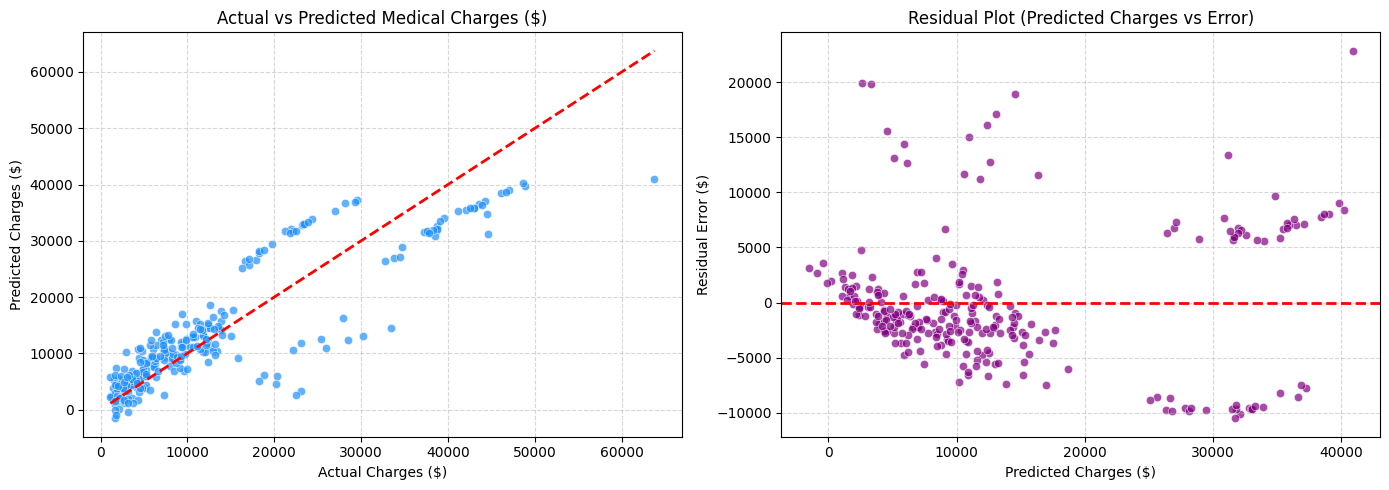

In [4]:
# Cell 4: Generate Evaluation Graphs
plt.figure(figsize=(14, 5))

# Graph 1: Actual vs Predicted Charges
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=y_pred_full, alpha=0.7, color='dodgerblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Medical Charges ($)')
plt.xlabel('Actual Charges ($)')
plt.ylabel('Predicted Charges ($)')
plt.grid(True, linestyle='--', alpha=0.5)

# Graph 2: Residual Plot (Error Distribution)
residuals = y_test - y_pred_full
plt.subplot(1, 2, 2)
sns.scatterplot(x=y_pred_full, y=residuals, alpha=0.7, color='purple')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.title('Residual Plot (Predicted Charges vs Error)')
plt.xlabel('Predicted Charges ($)')
plt.ylabel('Residual Error ($)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [5]:
# Cell 5: Model with Interaction Term (BMI x Smoker)
X_train_int = X_train.copy()
X_test_int = X_test.copy()

X_train_int['bmi_smoker'] = X_train_int['bmi'] * X_train_int['smoker']
X_test_int['bmi_smoker'] = X_test_int['bmi'] * X_test_int['smoker']

int_model = LinearRegression()
int_model.fit(X_train_int, y_train)

y_pred_int = int_model.predict(X_test_int)

r2_int = r2_score(y_test, y_pred_int)
mae_int = mean_absolute_error(y_test, y_pred_int)
rmse_int = np.sqrt(mean_squared_error(y_test, y_pred_int))

print("=== 3. INTERACTION MODEL RESULTS (BMI x Smoker) ===")
print(f"R2 Score: {r2_int:.4f}")
print(f"MAE:     ${mae_int:,.2f}")
print(f"RMSE:    ${rmse_int:,.2f}")

=== 3. INTERACTION MODEL RESULTS (BMI x Smoker) ===
R2 Score: 0.8653
MAE:     $2,756.90
RMSE:    $4,573.81


In [6]:
# Cell 6: Save Trained Model for Sarvesha's Web App
joblib.dump(int_model, 'model.pkl')

print("Model saved successfully as model.pkl!")

Model saved successfully as model.pkl!
